# Assignment B: Synthetic Data

Generate and visualize data with a true effect and data without a true effect.

## 1. Import libraries and set parameters

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
N_GROUP = 60
BASE_MEAN = 55
SD = 15

## 2. Define the synthetic data generator

In [6]:
def simulate_data(effect_size, seed):
    rng = np.random.default_rng(seed)
    n = N_GROUP * 2

    data = pd.DataFrame({
        "pitch": rng.choice(["low", "high"], n),
        "tempo": rng.choice(["slow", "fast"], n),
        "beat": rng.choice(["weak", "strong"], n),
        "mode": rng.choice(["minor", "major"], n),
    })

    data["condition"] = rng.permutation(
        ["matched"] * N_GROUP + ["mismatched"] * N_GROUP
    )

    means = BASE_MEAN + effect_size * (
        data["condition"] == "matched"
    ).astype(int)
    scores = rng.normal(loc=means, scale=SD, size=n)
    data["liking"] = np.clip(scores, 0, 100)

    return data

## 3. Create data with and without a true effect

In [7]:
data_effect = simulate_data(effect_size=10, seed=SEED)
data_null = simulate_data(effect_size=0, seed=SEED)

data_effect.head()

,pitch,tempo,beat,mode,condition,liking
0,low,slow,weak,major,matched,82.661178
1,high,fast,strong,major,mismatched,61.586300
2,high,fast,weak,minor,matched,91.159018
3,low,slow,strong,major,matched,71.584897
4,low,fast,strong,minor,mismatched,67.419823


## 4. Summarize and visualize the two datasets


True effect: +10 points
             mean    std  count
condition                      
matched     65.91  16.34     60
mismatched  54.79  13.93     60

No true effect: 0 points
             mean    std  count
condition                      
matched     55.91  16.34     60
mismatched  54.79  13.93     60


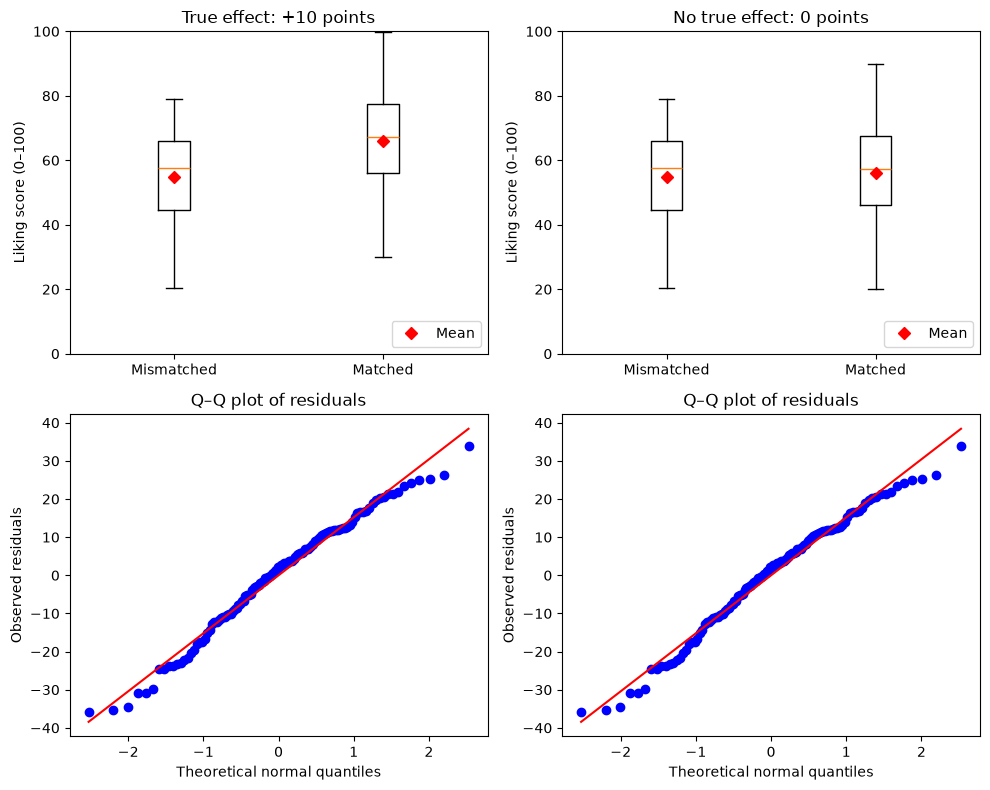

In [8]:
datasets = [
    ("True effect: +10 points", data_effect),
    ("No true effect: 0 points", data_null),
]

conditions = ["mismatched", "matched"]
labels = ["Mismatched", "Matched"]

mean_style = {
    "marker": "D",
    "markerfacecolor": "red",
    "markeredgecolor": "red",
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for col, (title, data) in enumerate(datasets):
    # Print descriptive statistics for each group.
    print(f"\n{title}")
    print(
        data.groupby("condition")["liking"]
        .agg(["mean", "std", "count"])
        .round(2)
    )

    groups = [
        data.loc[data["condition"] == condition, "liking"]
        for condition in conditions
    ]

    # Calculate residuals by subtracting each group's own mean.
    group_means = data.groupby("condition")["liking"].transform("mean")
    residuals = data["liking"] - group_means

    # Top row: compare group scores and show their means.
    ax = axes[0, col]
    box = ax.boxplot(groups, showmeans=True, meanprops=mean_style)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(labels)
    ax.set_title(title)
    ax.set_ylabel("Liking score (0–100)")
    ax.set_ylim(0, 100)
    ax.legend([box["means"][0]], ["Mean"], loc="lower right")

    # Bottom row: inspect the shape of the residuals.
    ax = axes[1, col]
    stats.probplot(residuals, dist="norm", plot=ax)
    ax.set_title("Q–Q plot of residuals")
    ax.set_xlabel("Theoretical normal quantiles")
    ax.set_ylabel("Observed residuals")

plt.tight_layout()
plt.show()